In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [3]:
import os

os.listdir()

['.ipynb_checkpoints',
 '.kilo',
 'cab fare .ipynb',
 'Customer segmentation.ipynb',
 'IMDB Movie Analysis',
 'P1_Assessment-{Aayush_Buchade}.zip',
 'Test.csv',
 'UrbanCabFare.csv']

In [5]:
df = pd.read_csv("UrbanCabFare.csv")

df.head()

,User_ID,Driver_Name,City,Ride_Date,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare
0,USER-21819-Bcbf,Patrick Sanchez,Pune,05-11-2025,0,Friday,26.21,Low,Hatchback,36,67,1.86,60,354.52,1.3,460.88
1,USER-79402-SBvr,Meredith Barnes,Mumbai,13-10-2025,2,Friday,21.08,High,Auto,9,17,1.89,50,282.96,1.3,367.85
2,USER-40781-yfJs,Ian Cooper,Bengaluru,16-06-2026,6,Sunday,25.34,High,Hatchback,94,149,1.59,75,344.08,1.3,447.30
3,USER-41316-rDOx,Amber Perez,Mumbai,15-10-2025,0,Monday,26.80,High,Auto,25,188,7.52,76,351.60,1.6,562.56
4,USER-76483-RuXX,Kimberly Sanchez,Chennai,06-09-2025,10,Friday,4.48,High,SUV,53,34,0.64,18,133.76,1.0,133.76


In [6]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (1000, 16)


In [7]:
print("Column names:")
print(df.columns.tolist())

Column names:
['User_ID', 'Driver_Name', 'City', 'Ride_Date', 'Hour_of_Day', 'Day_of_Week', 'Distance_km', 'Traffic_Level', 'Type_of_vehicle', 'No_of_active_drivers', 'Ride_Requests', 'Demand_Supply_Ratio', 'Trip_Duration', 'Base_Fare', 'Surge_Multiplier', 'Final_Fare']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               1000 non-null   str    
 1   Driver_Name           985 non-null    str    
 2   City                  1000 non-null   str    
 3   Ride_Date             1000 non-null   str    
 4   Hour_of_Day           1000 non-null   int64  
 5   Day_of_Week           1000 non-null   str    
 6   Distance_km           1000 non-null   float64
 7   Traffic_Level         1000 non-null   str    
 8   Type_of_vehicle       1000 non-null   str    
 9   No_of_active_drivers  1000 non-null   int64  
 10  Ride_Requests         1000 non-null   int64  
 11  Demand_Supply_Ratio   1000 non-null   float64
 12  Trip_Duration         1000 non-null   int64  
 13  Base_Fare             1000 non-null   float64
 14  Surge_Multiplier      1000 non-null   float64
 15  Final_Fare            1000 non-nu

In [9]:
df.describe()

,Hour_of_Day,Distance_km,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,11.651000,17.911070,52.52000,108.047000,3.569190,55.165000,257.477840,1.436200,370.238310
std,7.020576,9.634464,27.47334,55.394199,4.734492,27.946857,117.993113,0.343435,199.232597
min,0.000000,1.010000,5.00000,10.000000,0.100000,6.000000,27.120000,1.000000,32.540000
25%,5.750000,9.567500,28.00000,60.000000,1.157500,32.000000,159.650000,1.000000,208.205000
50%,12.000000,18.180000,54.00000,110.500000,2.040000,54.000000,256.740000,1.500000,338.580000
75%,18.000000,25.897500,76.00000,156.000000,4.022500,76.250000,352.230000,1.700000,493.767500
max,23.000000,34.990000,100.00000,200.000000,39.400000,122.000000,498.200000,2.000000,939.760000


In [10]:
df.isnull().sum()

User_ID                  0
Driver_Name             15
City                     0
Ride_Date                0
Hour_of_Day              0
Day_of_Week              0
Distance_km              0
Traffic_Level            0
Type_of_vehicle          0
No_of_active_drivers     0
Ride_Requests            0
Demand_Supply_Ratio      0
Trip_Duration            0
Base_Fare                0
Surge_Multiplier         0
Final_Fare               0
dtype: int64

In [11]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

Driver_Name             1.5
User_ID                 0.0
City                    0.0
Ride_Date               0.0
Hour_of_Day             0.0
Day_of_Week             0.0
Distance_km             0.0
Traffic_Level           0.0
Type_of_vehicle         0.0
No_of_active_drivers    0.0
Ride_Requests           0.0
Demand_Supply_Ratio     0.0
Trip_Duration           0.0
Base_Fare               0.0
Surge_Multiplier        0.0
Final_Fare              0.0
dtype: float64

In [12]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [13]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (1000, 16)


In [14]:
df.dtypes

User_ID                     str
Driver_Name                 str
City                        str
Ride_Date                   str
Hour_of_Day               int64
Day_of_Week                 str
Distance_km             float64
Traffic_Level               str
Type_of_vehicle             str
No_of_active_drivers      int64
Ride_Requests             int64
Demand_Supply_Ratio     float64
Trip_Duration             int64
Base_Fare               float64
Surge_Multiplier        float64
Final_Fare              float64
dtype: object

In [15]:
df = df.drop(columns=['User_ID', 'Driver_Name', 'Ride_Date'])

df.head()

,City,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Final_Fare
0,Pune,0,Friday,26.21,Low,Hatchback,36,67,1.86,60,354.52,1.3,460.88
1,Mumbai,2,Friday,21.08,High,Auto,9,17,1.89,50,282.96,1.3,367.85
2,Bengaluru,6,Sunday,25.34,High,Hatchback,94,149,1.59,75,344.08,1.3,447.30
3,Mumbai,0,Monday,26.80,High,Auto,25,188,7.52,76,351.60,1.6,562.56
4,Chennai,10,Friday,4.48,High,SUV,53,34,0.64,18,133.76,1.0,133.76


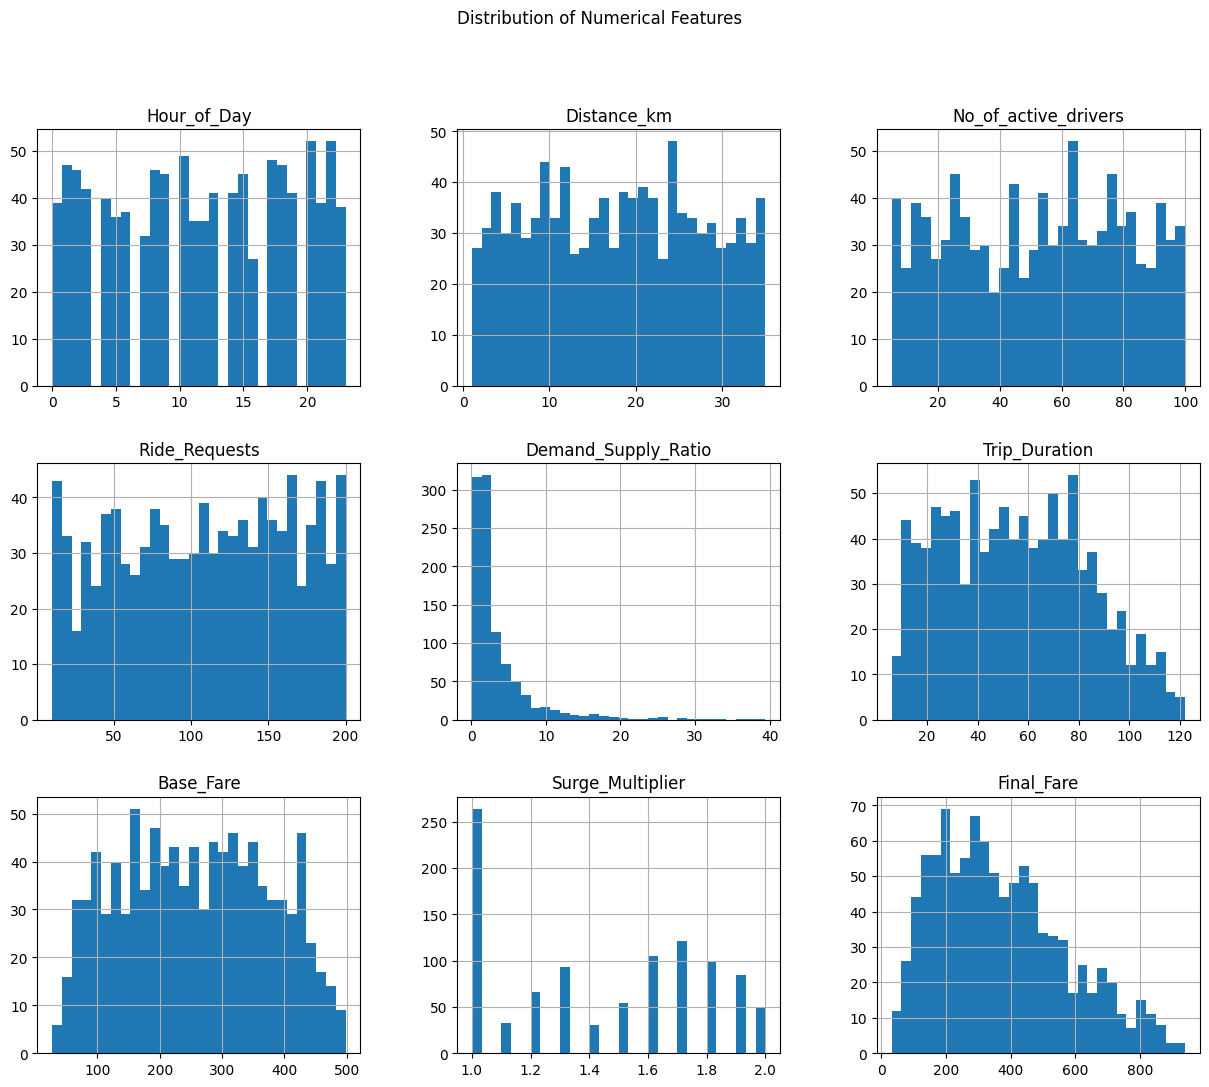

In [16]:
numerical_columns = [
    'Hour_of_Day',
    'Distance_km',
    'No_of_active_drivers',
    'Ride_Requests',
    'Demand_Supply_Ratio',
    'Trip_Duration',
    'Base_Fare',
    'Surge_Multiplier',
    'Final_Fare'
]

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")
plt.show()

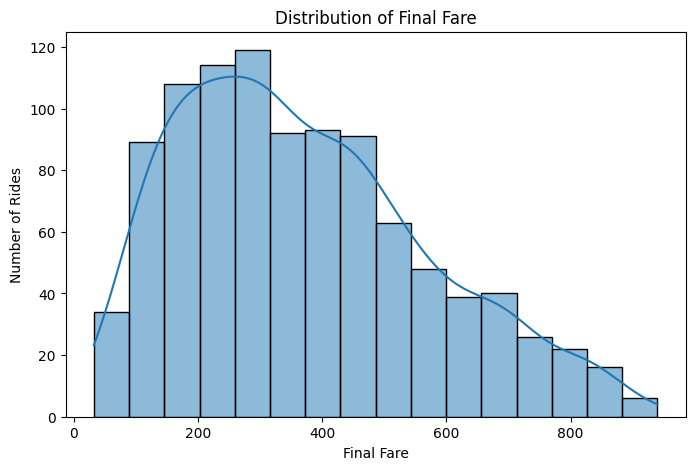

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Final_Fare'], kde=True)

plt.title("Distribution of Final Fare")
plt.xlabel("Final Fare")
plt.ylabel("Number of Rides")

plt.show()

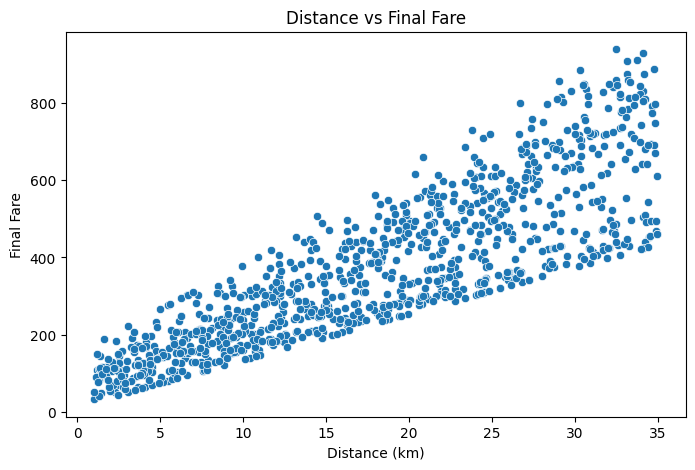

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Distance_km',
    y='Final_Fare'
)

plt.title("Distance vs Final Fare")
plt.xlabel("Distance (km)")
plt.ylabel("Final Fare")

plt.show()

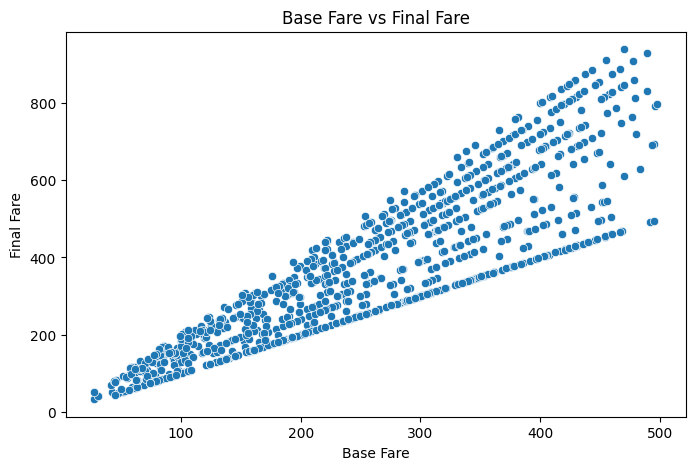

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Base_Fare',
    y='Final_Fare'
)

plt.title("Base Fare vs Final Fare")
plt.xlabel("Base Fare")
plt.ylabel("Final Fare")

plt.show()

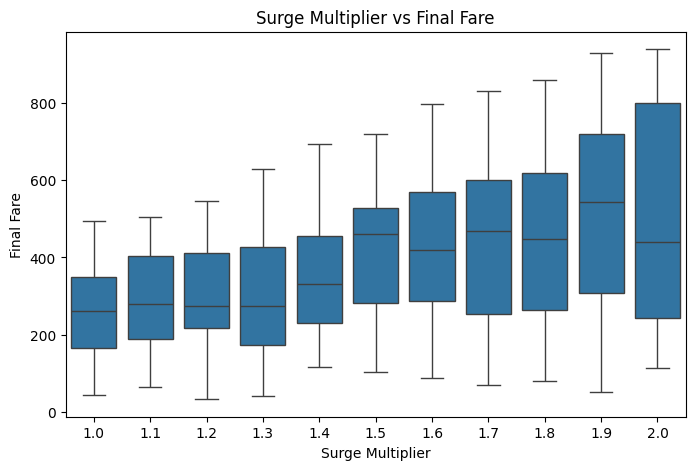

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Surge_Multiplier',
    y='Final_Fare'
)

plt.title("Surge Multiplier vs Final Fare")
plt.xlabel("Surge Multiplier")
plt.ylabel("Final Fare")

plt.show()

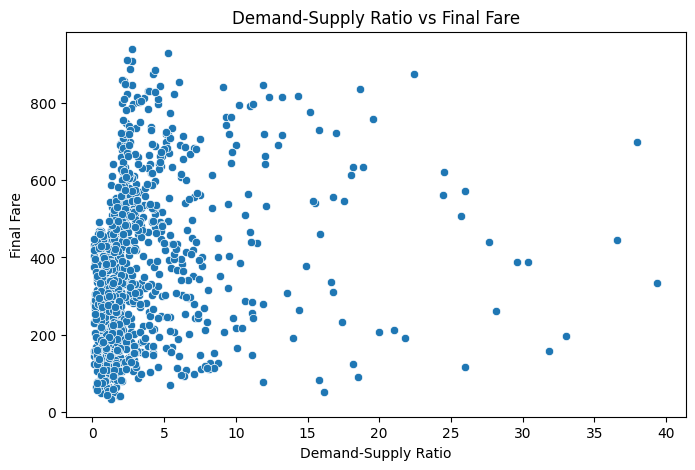

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Demand_Supply_Ratio',
    y='Final_Fare'
)

plt.title("Demand-Supply Ratio vs Final Fare")
plt.xlabel("Demand-Supply Ratio")
plt.ylabel("Final Fare")

plt.show()

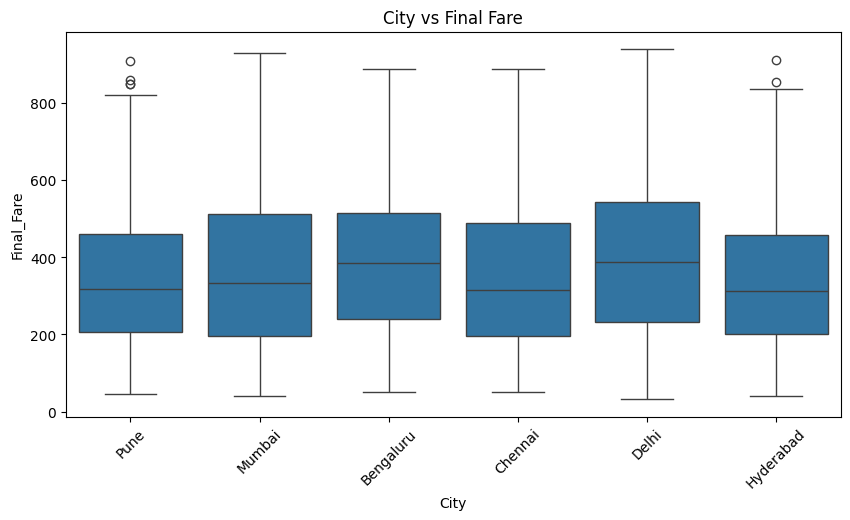

In [22]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='City',
    y='Final_Fare'
)

plt.title("City vs Final Fare")
plt.xticks(rotation=45)

plt.show()

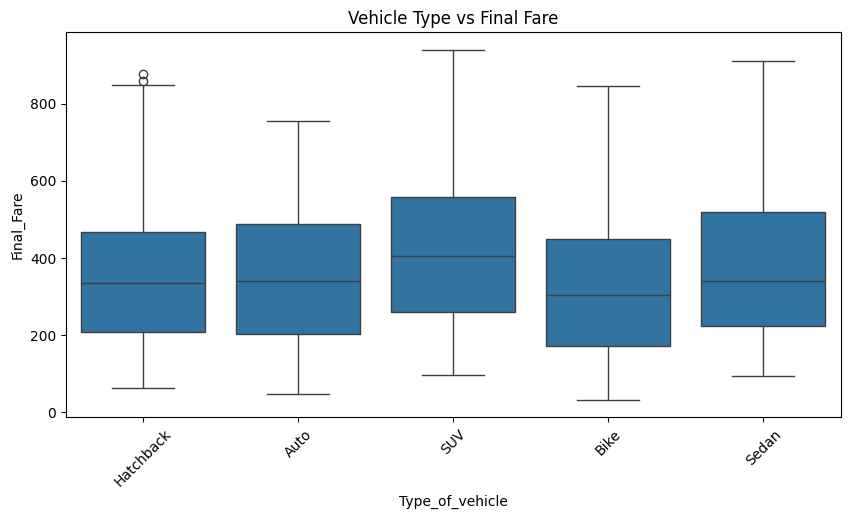

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='Type_of_vehicle',
    y='Final_Fare'
)

plt.title("Vehicle Type vs Final Fare")
plt.xticks(rotation=45)

plt.show()

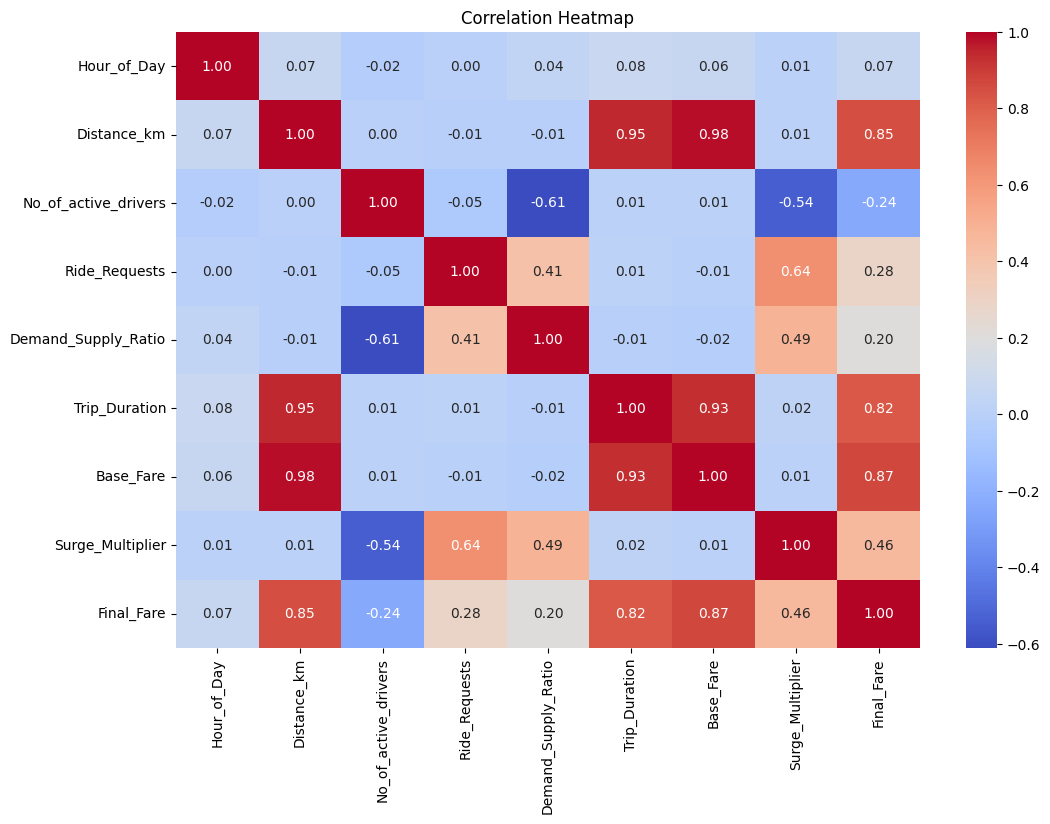

In [24]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

In [26]:
X = df.drop(columns=['Final_Fare'])

y = df['Final_Fare']

In [27]:
categorical_features = [
    'City',
    'Day_of_Week',
    'Traffic_Level',
    'Type_of_vehicle'
]

numerical_features = [
    'Hour_of_Day',
    'Distance_km',
    'No_of_active_drivers',
    'Ride_Requests',
    'Demand_Supply_Ratio',
    'Trip_Duration',
    'Base_Fare',
    'Surge_Multiplier'
]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 12)
Testing data: (200, 12)


In [29]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [30]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [31]:
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [32]:
linear_predictions = linear_model.predict(X_test)

In [33]:
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
rf_predictions = random_forest_model.predict(X_test)

In [35]:
gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            GradientBoostingRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

gradient_boosting_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [36]:
gb_predictions = gradient_boosting_model.predict(X_test)

In [37]:
def evaluate_model(model_name, y_true, y_pred):
    
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    return {
        'Model': model_name,
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    }

In [38]:
results = []

results.append(
    evaluate_model(
        'Linear Regression',
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        'Random Forest',
        y_test,
        rf_predictions
    )
)

results.append(
    evaluate_model(
        'Gradient Boosting',
        y_test,
        gb_predictions
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,RMSE,MAE,R2 Score
0,Linear Regression,40.163812,30.377852,0.957059
1,Random Forest,12.822676,8.617025,0.995623
2,Gradient Boosting,11.599960,8.513769,0.996418


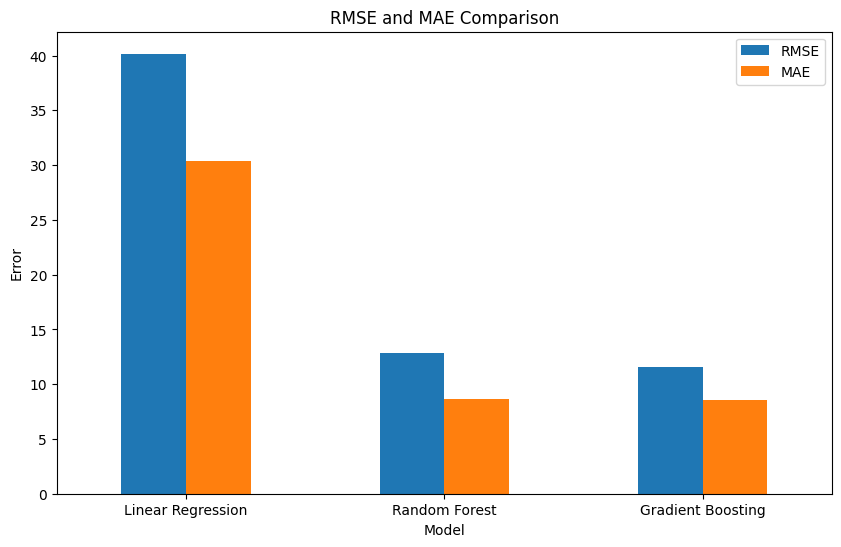

In [39]:
results_df.set_index('Model')[['RMSE', 'MAE']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("RMSE and MAE Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)

plt.show()

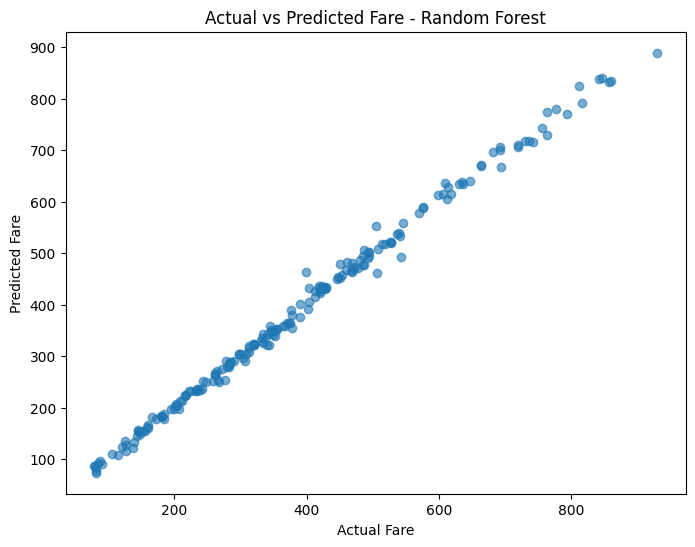

In [40]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Fare - Random Forest")

plt.show()

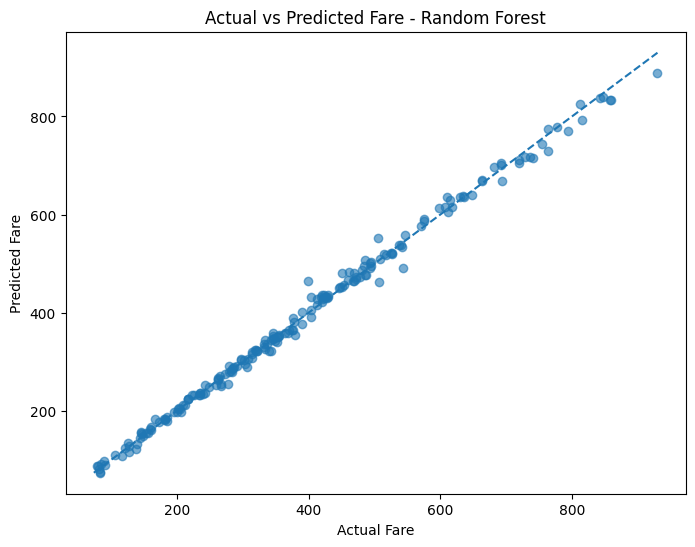

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6
)

minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title("Actual vs Predicted Fare - Random Forest")

plt.show()

In [43]:
gb_pipeline = gradient_boosting_model

gb_preprocessor = gb_pipeline.named_steps['preprocessor']
gb_model = gb_pipeline.named_steps['model']

gb_feature_names = gb_preprocessor.get_feature_names_out()

gb_importances = gb_model.feature_importances_

gb_importance_df = pd.DataFrame({
    'Feature': gb_feature_names,
    'Importance': gb_importances
})

gb_importance_df = gb_importance_df.sort_values(
    by='Importance',
    ascending=False
)

gb_importance_df.head(15)

,Feature,Importance
6,num__Base_Fare,0.759301
7,num__Surge_Multiplier,0.180902
4,num__Demand_Supply_Ratio,0.044306
1,num__Distance_km,0.015285
5,num__Trip_Duration,0.000078
2,num__No_of_active_drivers,0.000024
3,num__Ride_Requests,0.000022
16,cat__Day_of_Week_Saturday,0.000022
28,cat__Type_of_vehicle_SUV,0.000016
26,cat__Type_of_vehicle_Bike,0.000013


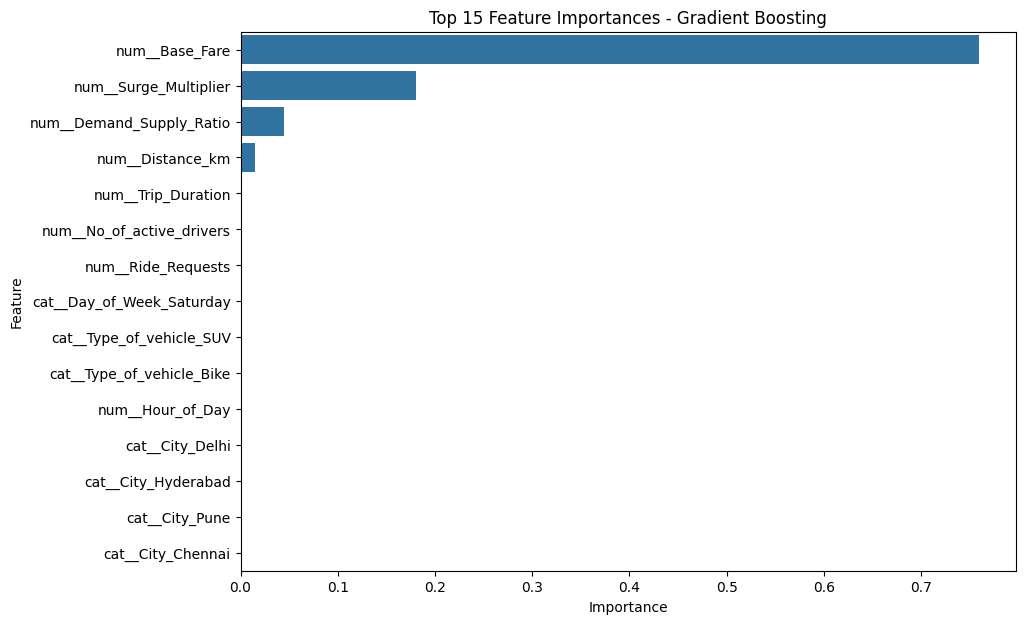

In [44]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=gb_importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Feature Importances - Gradient Boosting")

plt.show()

In [45]:
prediction_results = X_test.copy()

prediction_results['Actual_Fare'] = y_test.values
prediction_results['Predicted_Fare'] = rf_predictions

prediction_results.head(10)

,City,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Actual_Fare,Predicted_Fare
521,Hyderabad,21,Friday,30.92,Jam,Sedan,98,43,0.44,93,421.04,1.0,421.04,426.9940
737,Bengaluru,14,Sunday,1.85,Jam,Sedan,63,161,2.56,11,72.20,1.9,137.18,121.2568
740,Mumbai,16,Friday,21.81,Low,Bike,25,106,4.24,63,276.72,1.9,525.77,521.2375
660,Delhi,8,Friday,24.82,Medium,SUV,67,58,0.87,65,377.84,1.0,377.84,380.3644
411,Delhi,9,Monday,12.13,Jam,Hatchback,75,126,1.68,29,185.56,1.2,222.67,232.7349
678,Hyderabad,5,Thursday,31.02,Low,SUV,84,103,1.23,103,452.24,1.2,542.69,491.8653
626,Chennai,23,Thursday,24.23,Low,Sedan,29,137,4.72,80,340.76,1.9,647.44,640.4747
513,Bengaluru,4,Monday,33.28,Low,Auto,70,29,0.41,105,429.36,1.0,429.36,432.0468
859,Pune,18,Thursday,33.17,Jam,Sedan,78,11,0.14,89,448.04,1.0,448.04,452.9233
136,Pune,21,Saturday,14.46,High,SUV,6,154,25.67,49,253.52,2.0,507.04,461.9966


In [46]:
prediction_results['Error'] = (
    prediction_results['Actual_Fare'] -
    prediction_results['Predicted_Fare']
)

prediction_results.head()

,City,Hour_of_Day,Day_of_Week,Distance_km,Traffic_Level,Type_of_vehicle,No_of_active_drivers,Ride_Requests,Demand_Supply_Ratio,Trip_Duration,Base_Fare,Surge_Multiplier,Actual_Fare,Predicted_Fare,Error
521,Hyderabad,21,Friday,30.92,Jam,Sedan,98,43,0.44,93,421.04,1.0,421.04,426.9940,-5.9540
737,Bengaluru,14,Sunday,1.85,Jam,Sedan,63,161,2.56,11,72.20,1.9,137.18,121.2568,15.9232
740,Mumbai,16,Friday,21.81,Low,Bike,25,106,4.24,63,276.72,1.9,525.77,521.2375,4.5325
660,Delhi,8,Friday,24.82,Medium,SUV,67,58,0.87,65,377.84,1.0,377.84,380.3644,-2.5244
411,Delhi,9,Monday,12.13,Jam,Hatchback,75,126,1.68,29,185.56,1.2,222.67,232.7349,-10.0649


In [48]:
best_rmse_model = results_df.loc[
    results_df['RMSE'].idxmin(),
    'Model'
]

best_mae_model = results_df.loc[
    results_df['MAE'].idxmin(),
    'Model'
]

best_r2_model = results_df.loc[
    results_df['R2 Score'].idxmax(),
    'Model'
]

print("Lowest RMSE:", best_rmse_model)
print("Lowest MAE:", best_mae_model)
print("Highest R²:", best_r2_model)

Lowest RMSE: Gradient Boosting
Lowest MAE: Gradient Boosting
Highest R²: Gradient Boosting
